<div style="border:solid green 2px; padding: 20px">
Мария, привет и хорошего дня! <br>
Меня зовут Сергей Дроздов, и я буду проверять твой проект. Предлагаю общаться на «ты». Если тебе удобнее общаться на "Вы", просто дай знать. 

Ты уже проделал большую работу над проектом, но давай сделаем его еще лучше. Ниже ты найдешь мои комментарии - пожалуйста, не перемещай, не изменяй и не удаляй их. Я буду использовать цветовую разметку:

<div class="alert alert-danger">
<b>Комментарий ревьюера: &#10060; </b> Так будут выделены комментарии с указаниями, обязательными к выполнению. Без их выполнения проект не будет принят. </div>

<div class="alert alert-warning">
<b>Комментарий ревьюера:
&#9888;</b> Так будут выделены некритичные замечания. Их отработка позволит улучшить качество твоего проекта.
</div>

<div class="alert alert-success">
<b>Комментарий ревьюера:
&#9989;</b> Так будут выделены остальные комментарии, полезные лайфхаки и ссылки на сторонние ресурсы </div>
    <br>
    
<div style="border-radius: 15px; border: 3px solid indigo; padding: 15px;background:rgb(185, 176, 207)">
<b>Итоговый комментарий ревьюера:
</b> Так будут выделены итоговые комментарии.
</div>

Для наиболее эффективной и оперативной работы над проектом, мне хотелось бы иметь обратную связь. Не стесняйся задавать вопросы. Если ты что-либо меняешь в проекте, пожалуйста, комментируй это. Мне будет легче отследить изменения, если ты выделишь свои комментарии:
<div class="alert alert-info"> <b>Комментарий студента:</b> Например так</div>

# Прогнозирование длительности использования пользователем услуг связи и интернета

Оператор связи «Ниединогоразрыва.ком» хочет научиться прогнозировать отток клиентов. Если выяснится, что пользователь планирует уйти, ему будут предложены промокоды и специальные условия. Команда оператора собрала персональные данные о некоторых клиентах, информацию об их тарифах и договорах.

Соответственно, задачей данного проекта является создание модели, которая учитывая персональные данные пользователя и подключенные тарифы смогла бы предсказать уровень его лояльности.

<div class="alert alert-success">
<b>Комментарий ревьюера:
&#9989;</b> Хорошо! Название и описание на месте!</div>
    <br>

# Загрузка данных и их предобработка

In [85]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import datetime as dt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import roc_auc_score, roc_curve
from catboost import CatBoostClassifier

In [86]:
import scipy.stats as ss

def cramers_corrected_stat(confusion_matrix):
    chi2 = ss.chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2/n
    r,k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))    
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2corr / min( (kcorr-1), (rcorr-1)))

In [87]:
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x,y)
    chi2 = ss.chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2/n
    r,k = confusion_matrix.shape
    phi2corr = max(0, phi2-((k-1)*(r-1))/(n-1))
    rcorr = r-((r-1)**2)/(n-1)
    kcorr = k-((k-1)**2)/(n-1)
    return np.sqrt(phi2corr/min((kcorr-1),(rcorr-1)))

In [88]:
contract_df = pd.read_csv('/datasets/final_provider/contract.csv')
personal_df = pd.read_csv('/datasets/final_provider/personal.csv')
internet_df = pd.read_csv('/datasets/final_provider/internet.csv')
phone_df = pd.read_csv('/datasets/final_provider/phone.csv')

In [89]:
contract_df.head()

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65


In [90]:
contract_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
dtypes: float64(1), object(7)
memory usage: 440.3+ KB


In [91]:
contract_df.loc[contract_df['TotalCharges'] == ' ', 'TotalCharges'] = contract_df.loc[contract_df['TotalCharges'] == ' ', 'MonthlyCharges']

In [92]:
contract_df['TotalCharges'] = contract_df['TotalCharges'].astype('float')

In [93]:
contract_df['BeginDate'] = pd.to_datetime(
    contract_df['BeginDate'], format='%Y-%m-%d'
)

In [94]:
contract_df['stopped'] = (contract_df['EndDate'] == 'No').astype(int)

In [95]:
# contract_df.loc[contract_df['EndDate'] == 'No', 'EndDate'] = '2020-02-01 13:02:00'

<div class="alert alert-danger">
<b>Комментарий ревьюера: &#10060; </b> Обрати, пожалуйста, внимание на дату выгрузки из бд </div>

Имеется в виду не то время? А где ее по-хорошему нужно смотреть?

<div class="alert alert-success">
<b>Комментарий ревьюера V2:
&#9989;</b> Да,дата выгрузки - 1 февраля 2020. В условии задачи </div>
    <br>

In [96]:
contract_df.loc[contract_df['EndDate'] == 'No', 'EndDate'] = '2020-02-01 00:00:00'

In [97]:
contract_df['EndDate'] = pd.to_datetime(
    contract_df['EndDate'], format='%Y-%m-%d %H:%M:%S'
)

In [98]:
contract_df.isna().sum()

customerID          0
BeginDate           0
EndDate             0
Type                0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
stopped             0
dtype: int64

In [99]:
contract_df.duplicated().sum()

0

In [100]:
contract_df['duration'] = (contract_df['EndDate'] - contract_df['BeginDate']).dt.days


In [101]:
contract_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customerID        7043 non-null   object        
 1   BeginDate         7043 non-null   datetime64[ns]
 2   EndDate           7043 non-null   datetime64[ns]
 3   Type              7043 non-null   object        
 4   PaperlessBilling  7043 non-null   object        
 5   PaymentMethod     7043 non-null   object        
 6   MonthlyCharges    7043 non-null   float64       
 7   TotalCharges      7043 non-null   float64       
 8   stopped           7043 non-null   int64         
 9   duration          7043 non-null   int64         
dtypes: datetime64[ns](2), float64(2), int64(2), object(4)
memory usage: 550.4+ KB


In [102]:
contract_df.head()

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,stopped,duration
0,7590-VHVEG,2020-01-01,2020-02-01,Month-to-month,Yes,Electronic check,29.85,29.85,1,31
1,5575-GNVDE,2017-04-01,2020-02-01,One year,No,Mailed check,56.95,1889.50,1,1036
2,3668-QPYBK,2019-10-01,2019-12-01,Month-to-month,Yes,Mailed check,53.85,108.15,0,61
3,7795-CFOCW,2016-05-01,2020-02-01,One year,No,Bank transfer (automatic),42.30,1840.75,1,1371
4,9237-HQITU,2019-09-01,2019-11-01,Month-to-month,Yes,Electronic check,70.70,151.65,0,61


In [103]:
personal_df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No
3,7795-CFOCW,Male,0,No,No
4,9237-HQITU,Female,0,No,No


In [104]:
personal_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     7043 non-null   object
 1   gender         7043 non-null   object
 2   SeniorCitizen  7043 non-null   int64 
 3   Partner        7043 non-null   object
 4   Dependents     7043 non-null   object
dtypes: int64(1), object(4)
memory usage: 275.2+ KB


In [105]:
personal_df.isna().sum()

customerID       0
gender           0
SeniorCitizen    0
Partner          0
Dependents       0
dtype: int64

In [106]:
personal_df.duplicated().sum()

0

In [107]:
internet_df.head()

,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,Fiber optic,No,No,No,No,No,No


In [108]:
internet_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5517 entries, 0 to 5516
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   customerID        5517 non-null   object
 1   InternetService   5517 non-null   object
 2   OnlineSecurity    5517 non-null   object
 3   OnlineBackup      5517 non-null   object
 4   DeviceProtection  5517 non-null   object
 5   TechSupport       5517 non-null   object
 6   StreamingTV       5517 non-null   object
 7   StreamingMovies   5517 non-null   object
dtypes: object(8)
memory usage: 344.9+ KB


In [109]:
internet_df.isna().sum()

customerID          0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
dtype: int64

In [110]:
internet_df.duplicated().sum()

0

In [111]:
phone_df.head()

,customerID,MultipleLines
0,5575-GNVDE,No
1,3668-QPYBK,No
2,9237-HQITU,No
3,9305-CDSKC,Yes
4,1452-KIOVK,Yes


In [112]:
phone_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6361 entries, 0 to 6360
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     6361 non-null   object
 1   MultipleLines  6361 non-null   object
dtypes: object(2)
memory usage: 99.5+ KB


In [113]:
phone_df.isna().sum()

customerID       0
MultipleLines    0
dtype: int64

In [114]:
phone_df.duplicated().sum()

0

Предварительные выводы

Датасеты довольно качественные, в них нет явных пропусков и дубликатов.

В процессе обработки contract_df были изменены типы данных: TotalCharges на float, BeginDate и EndDate на datetime.

Был создан столбец duration, в котором указана длительность использования пользователями услуг оператора.

<div class="alert alert-success">
<b>Комментарий ревьюера:
&#9989;</b> Хорошо! </div>
    <br>

Уточняющие вопросы

- Правильно ли обозначить столбец duration как таргет и тогда решать задачу регрессии?

<div class="alert alert-success">
<b>Комментарий ревьюера:
&#9989;</b> Нет, таргет у нас - ушел клиент или нет(end_date) </div>
    <br>

# План работы

- объединить датасеты по столбцу customerID, так чтобы не произошло утечки данных.
- заполнить образовавшиеся пропуски выбранными значениями, там где их мало, удалить.
- провести исследовательский анализ данных и визуализировать нужные закономерности в данных.
- провести аналих признаков на мультиколлинеарность: посторить матрицу корреляции для количественных признаков и использовать Cramer's V для категориальных.
- провести проверку на дисбаланс классов.

- разбить выборку на обучающую и тестовую.
- провести кодировку и масштабирование признаков.
- обучить 2 модели, одна из них бустинговая.
- подобрать гиперпараметры с помощью GridSearchCV.
- выбрать итоговую модель по результатам кросс-валидации.
- проверить качество итоговой модели на тестовой выборке с помощью метрики ROC-AUC.
- построить ROC-кривую.
- построить матрицу ошибок.

- подвести итоги.


<div class="alert alert-success">
<b>Комментарий ревьюера:
&#9989;</b> Хороший план! </div>
    <br>

# Объединение датасетов

In [115]:
contract_df.info()
personal_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customerID        7043 non-null   object        
 1   BeginDate         7043 non-null   datetime64[ns]
 2   EndDate           7043 non-null   datetime64[ns]
 3   Type              7043 non-null   object        
 4   PaperlessBilling  7043 non-null   object        
 5   PaymentMethod     7043 non-null   object        
 6   MonthlyCharges    7043 non-null   float64       
 7   TotalCharges      7043 non-null   float64       
 8   stopped           7043 non-null   int64         
 9   duration          7043 non-null   int64         
dtypes: datetime64[ns](2), float64(2), int64(2), object(4)
memory usage: 550.4+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------  

In [116]:
contract_personal_df = contract_df.merge(personal_df, on='customerID', how='outer')

In [117]:
internet_cp_df = contract_personal_df.merge(internet_df, on='customerID', how='outer')

In [118]:
df = internet_cp_df.merge(phone_df, on='customerID', how='outer')

In [119]:
df.head()

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,stopped,duration,...,Partner,Dependents,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,MultipleLines
0,7590-VHVEG,2020-01-01,2020-02-01,Month-to-month,Yes,Electronic check,29.85,29.85,1,31,...,Yes,No,DSL,No,Yes,No,No,No,No,NaN
1,5575-GNVDE,2017-04-01,2020-02-01,One year,No,Mailed check,56.95,1889.50,1,1036,...,No,No,DSL,Yes,No,Yes,No,No,No,No
2,3668-QPYBK,2019-10-01,2019-12-01,Month-to-month,Yes,Mailed check,53.85,108.15,0,61,...,No,No,DSL,Yes,Yes,No,No,No,No,No
3,7795-CFOCW,2016-05-01,2020-02-01,One year,No,Bank transfer (automatic),42.30,1840.75,1,1371,...,No,No,DSL,Yes,No,Yes,Yes,No,No,NaN
4,9237-HQITU,2019-09-01,2019-11-01,Month-to-month,Yes,Electronic check,70.70,151.65,0,61,...,No,No,Fiber optic,No,No,No,No,No,No,No


In [120]:
df.isna().sum()

customerID             0
BeginDate              0
EndDate                0
Type                   0
PaperlessBilling       0
PaymentMethod          0
MonthlyCharges         0
TotalCharges           0
stopped                0
duration               0
gender                 0
SeniorCitizen          0
Partner                0
Dependents             0
InternetService     1526
OnlineSecurity      1526
OnlineBackup        1526
DeviceProtection    1526
TechSupport         1526
StreamingTV         1526
StreamingMovies     1526
MultipleLines        682
dtype: int64

<div class="alert alert-success">
<b>Комментарий ревьюера:
&#9989;</b> Отлично, данные объединены корректно! </div>
    <br>

In [121]:
na_columns = ['InternetService', 'OnlineSecurity', 'OnlineBackup', 
              'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'MultipleLines']
for i in na_columns:
    df[i] = df[i].fillna('No')
df.isna().sum()

customerID          0
BeginDate           0
EndDate             0
Type                0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
stopped             0
duration            0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
MultipleLines       0
dtype: int64

<div class="alert alert-success">
<b>Комментарий ревьюера:
&#9989;</b> Хорошо! </div>
    <br>

In [122]:
categorical = ['Type', 'PaperlessBilling', 'PaymentMethod', 'gender', 'SeniorCitizen', 'Partner',
              'Dependents', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
              'TechSupport', 'StreamingTV', 'StreamingMovies', 'MultipleLines']
quantitive = ['BeginDate', 'EndDate', 'MonthlyCharges', 'TotalCharges', 'duration']

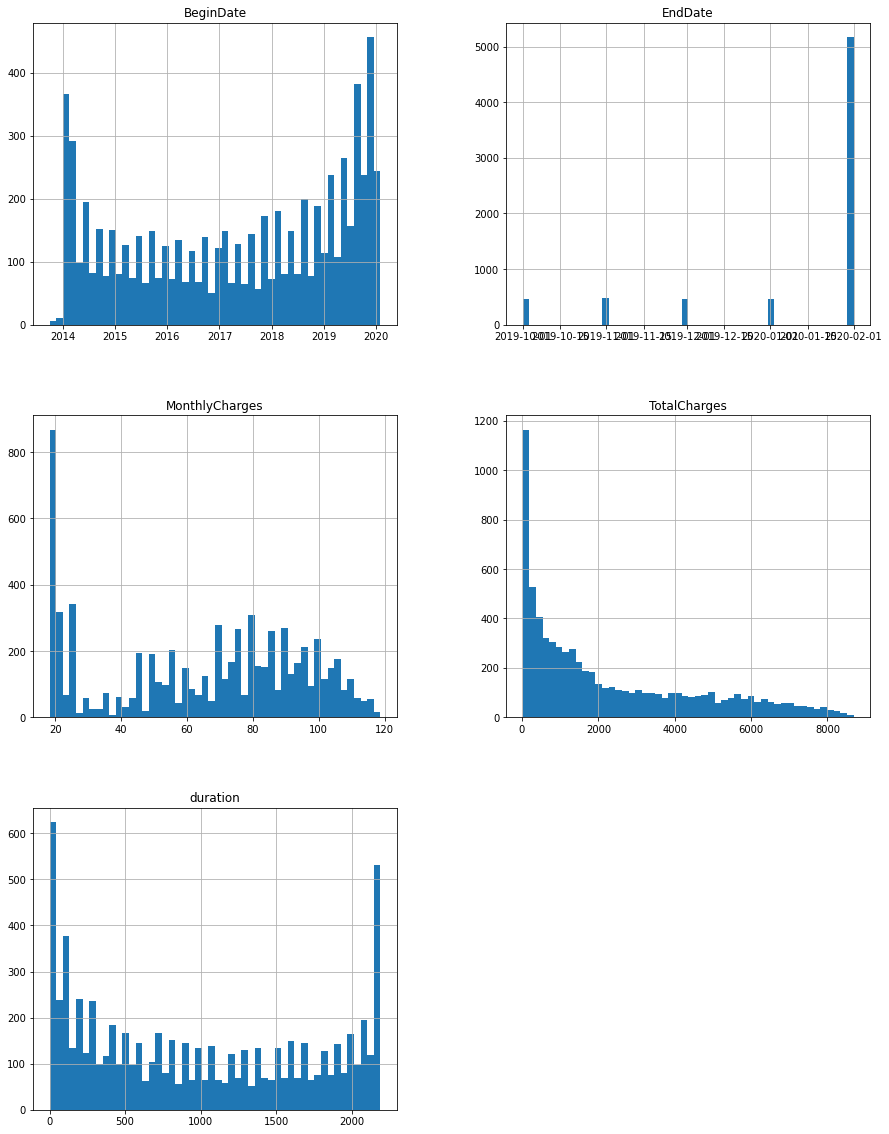

In [123]:
df[quantitive].hist(bins=50, figsize=(15, 20))
plt.show();

Популярность сервиса последнее время растет

Наибольшее количество людей пользуются минимумом услуг и мало платят.

<div class="alert alert-success">
<b>Комментарий ревьюера V2:
&#9989;</b> Хорошо! </div>
    <br>

<AxesSubplot:>

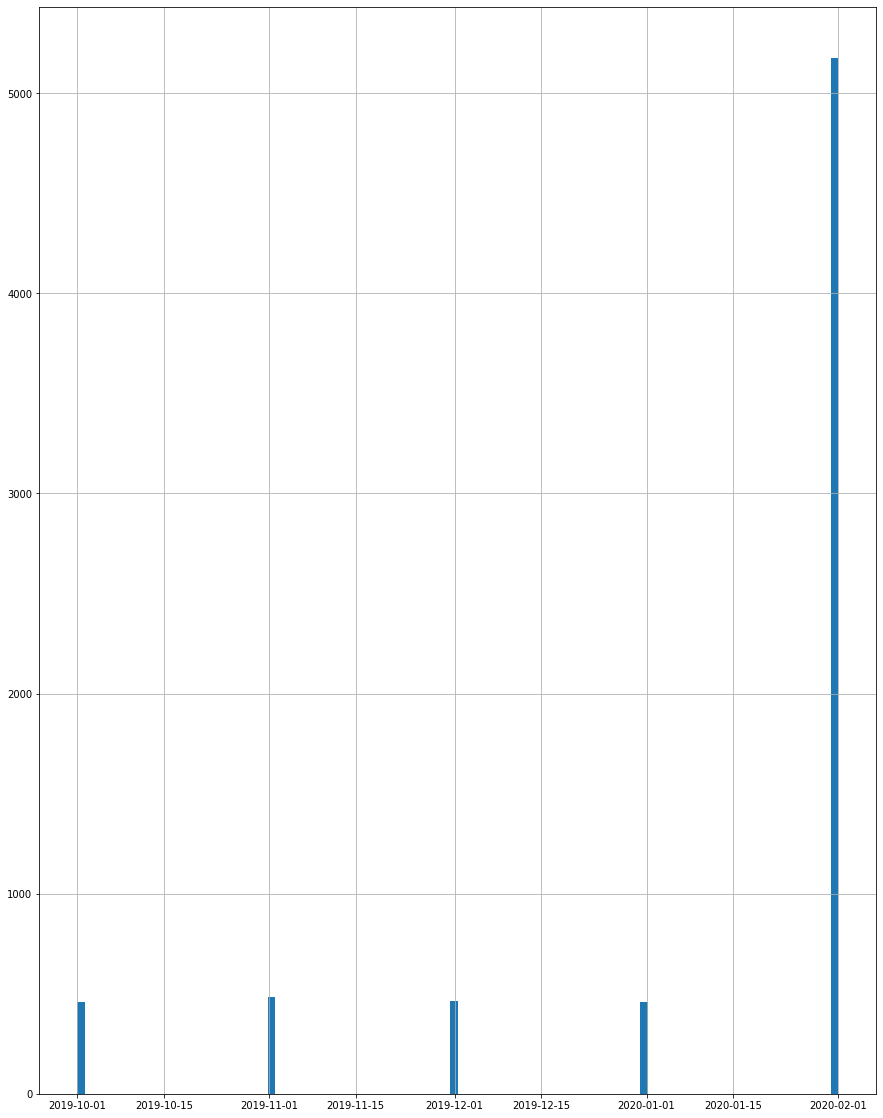

In [124]:
df['EndDate'].hist(bins=100, figsize=(15, 20))

<AxesSubplot:>

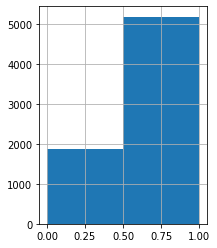

In [125]:
df['stopped'].hist(bins=2, figsize=(3, 4))

<AxesSubplot:>

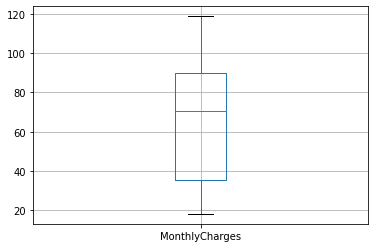

In [126]:
df.boxplot(column='MonthlyCharges')

<AxesSubplot:>

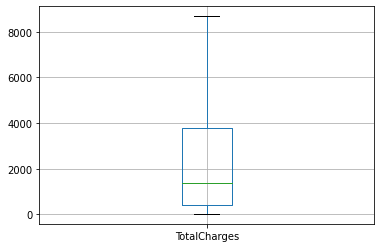

In [127]:
df.boxplot(column='TotalCharges')

<div class="alert alert-danger">
<b>Комментарий ревьюера: &#10060; </b> Стоит добавить выводы по результатам анализа. Также не забывай про подписи к графикам. Некоторые графики не информативны. Для pairplot лучше использовать разбивку по таргету(hue)</div>

<div class="alert alert-danger">
<b>Комментарий ревьюера V2: &#10060; </b> Хорошо! Давай немного подправим график!</div>

Text(0.5, 1.08, 'Корреляция количественных признаков с учетом целевого признака')

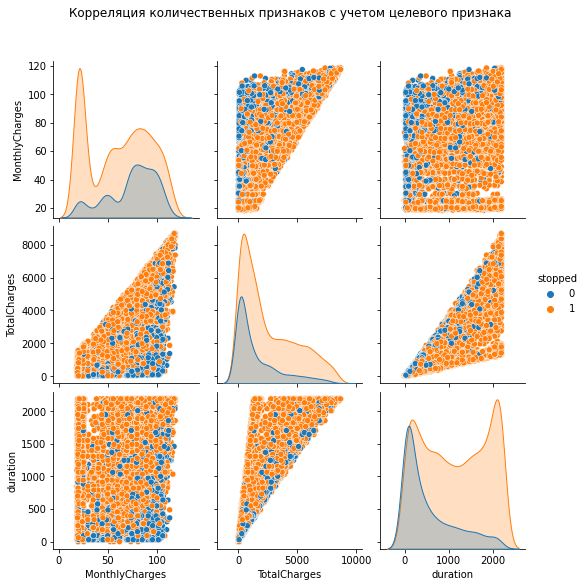

In [128]:

g = sns.pairplot(df, hue='stopped', vars=['MonthlyCharges', 'TotalCharges', 'duration'])
g.fig.suptitle('Корреляция количественных признаков с учетом целевого признака', y=1.08)

Довольно быстро прекращают пользоваться сервисом часть людей, которые много платят

<AxesSubplot:title={'center':'Корреляция количественных признаков'}>

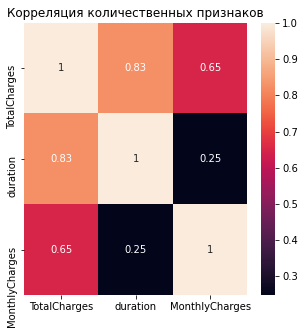

In [129]:
plt.figure(figsize=(5,5))
plt.title('Корреляция количественных признаков')
sns.heatmap(df[['TotalCharges', 'duration', 'MonthlyCharges']].corr().sort_values(by='TotalCharges', ascending=False), annot=True)

Заметна сильная положительная корреляция между продолжительностью пользования сервисом и величиной оплаты

<div class="alert alert-danger">
<b>Комментарий ревьюера: &#10060; </b> В корреляцию Пирсона попал бинарный таргет и категориальный признак</div>

<div class="alert alert-success">
<b>Комментарий ревьюера V2:
&#9989;</b> Хорошо! </div>
    <br>

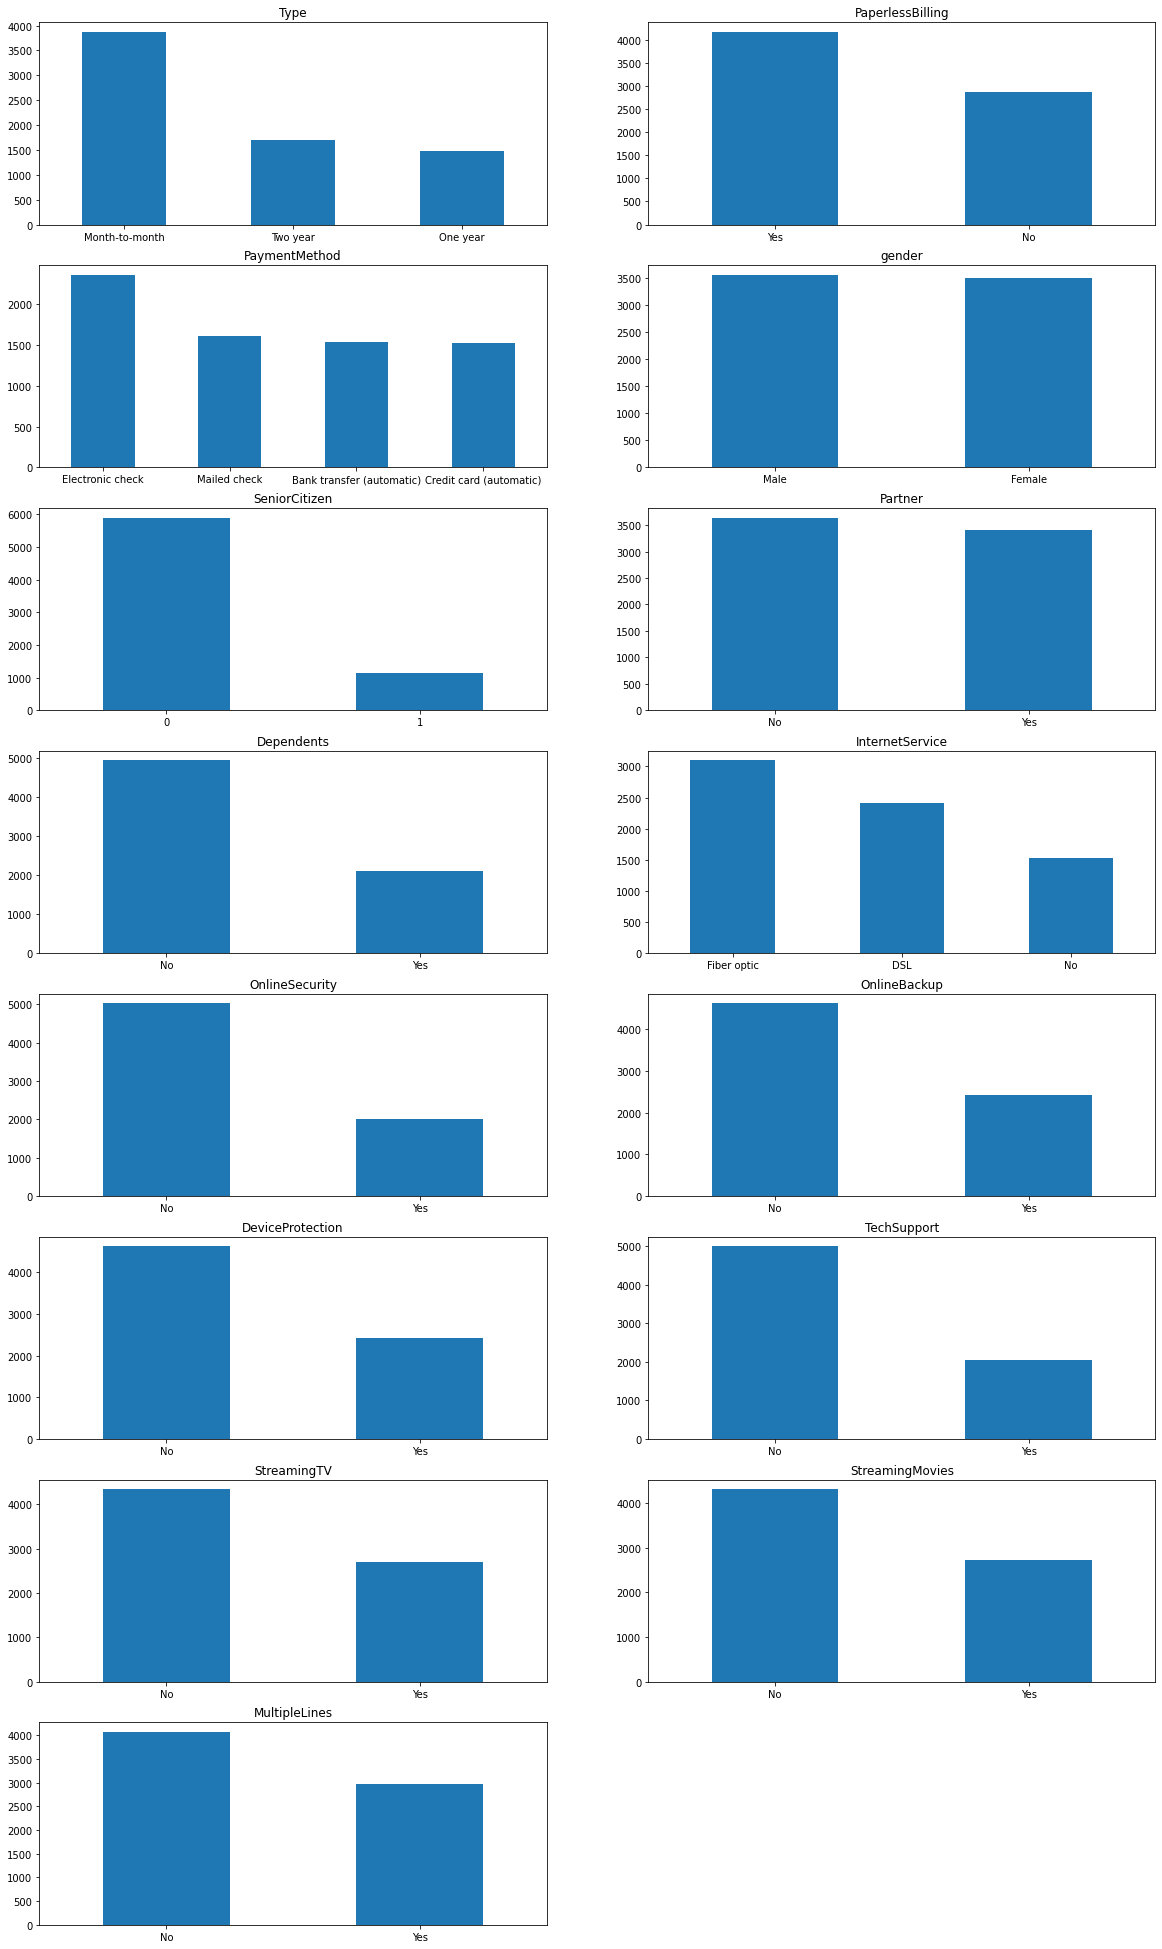

In [130]:
cs = 2
rows = int(np.ceil(len(categorical) / cs))
plt.figure(figsize=(20, 35))
for idx, column in enumerate(categorical):
    ax = plt.subplot(rows, cs, idx + 1)  
    df[column].value_counts().plot(
        kind='bar', 
        title=column, 
        ax=ax,
        rot=0)       
plt.show()

Из распределения категориальных признаков можно заключить, что
- помесячная оплата наиболее популярная
- наиболее востребованный способ оплаты - электронный
- наиболее популярный интерент-сервис - Fiber optic
- дополнительными сервисами пользуется меньшинство

<div class="alert alert-success">
<b>Комментарий ревьюера V2:
&#9989;</b> Хорошо! </div>
    <br>

In [131]:
confusion_mx = pd.crosstab(df['stopped'], [df[i] for i in categorical])

In [132]:
print(cramers_corrected_stat(confusion_mx))

0.3356563012200505


In [133]:
mx = []
for i in categorical:
    lst = []
    for j in categorical:
        lst.append(cramers_v(df[i], df[j]))
    mx.append(lst)                  

In [134]:
mx_df = pd.DataFrame(mx, columns=categorical, index=categorical)
print(mx_df)

                      Type  PaperlessBilling  PaymentMethod    gender  \
Type              1.000000          0.176857       0.265892  0.000000   
PaperlessBilling  0.176857          0.999706       0.247878  0.000000   
PaymentMethod     0.265892          0.247878       1.000000  0.000000   
gender            0.000000          0.000000       0.000000  0.999716   
SeniorCitizen     0.142888          0.155693       0.194908  0.000000   
Partner           0.295580          0.008414       0.161460  0.000000   
Dependents        0.243647          0.110429       0.149335  0.000000   
InternetService   0.206263          0.378079       0.312486  0.000000   
OnlineSecurity    0.250911          0.000000       0.174820  0.011710   
OnlineBackup      0.163738          0.125878       0.187991  0.006290   
DeviceProtection  0.227232          0.102812       0.204473  0.000000   
TechSupport       0.296005          0.035624       0.181002  0.000000   
StreamingTV       0.111052          0.223242       

<AxesSubplot:title={'center':'Корреляция категориальных признаков'}>

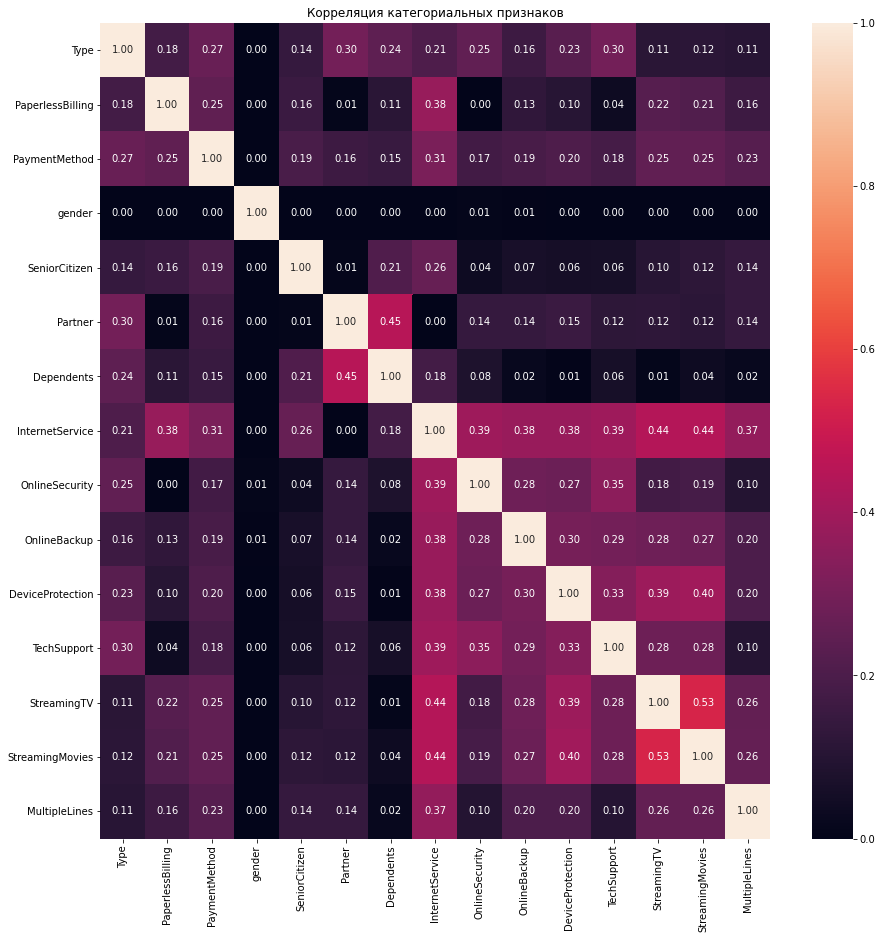

In [135]:
plt.figure(figsize=(15,15))
plt.title('Корреляция категориальных признаков')
sns.heatmap(mx_df, annot=True, fmt='.2f')

Можем заметить, что все значения приемлемые, мультиколлинеарности не наблюдается.

<div class="alert alert-success">
<b>Комментарий ревьюера V2:
&#9989;</b> Хорошо! </div>
    <br>

<div class="alert alert-danger">
<b>Комментарий ревьюера: &#10060; </b>Давай построим матрицу корреляции<a href = "https://towardsdatascience.com/the-search-for-categorical-correlation-a1cf7f1888c9">Пример построения heatmap</a>. Также можешь посмотреть библиотеку phik  </div>

In [136]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customerID        7043 non-null   object        
 1   BeginDate         7043 non-null   datetime64[ns]
 2   EndDate           7043 non-null   datetime64[ns]
 3   Type              7043 non-null   object        
 4   PaperlessBilling  7043 non-null   object        
 5   PaymentMethod     7043 non-null   object        
 6   MonthlyCharges    7043 non-null   float64       
 7   TotalCharges      7043 non-null   float64       
 8   stopped           7043 non-null   int64         
 9   duration          7043 non-null   int64         
 10  gender            7043 non-null   object        
 11  SeniorCitizen     7043 non-null   int64         
 12  Partner           7043 non-null   object        
 13  Dependents        7043 non-null   object        
 14  InternetService   7043 n

In [137]:
df = df.drop(columns=['BeginDate', 'EndDate', 'customerID'])

In [138]:
target = df['stopped'] 
features = df.drop(columns=['stopped'])

<div class="alert alert-success">
<b>Комментарий ревьюера:
&#9989;</b> Хорошо! </div>
    <br>

In [139]:
RANDOM_STATE = 130323

In [140]:
features_train, features_test, target_train, target_test = train_test_split(features, target,
                                                                            test_size=0.25, random_state=RANDOM_STATE)

In [141]:
features_train_cb, features_test_cb = features_train, features_test

In [142]:
categorial = ['Type', 'PaperlessBilling', 'PaymentMethod', 'gender', 'Partner',
              'Dependents', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
              'TechSupport', 'StreamingTV', 'StreamingMovies', 'MultipleLines']

In [143]:
encoder_ohe = OneHotEncoder(drop='first', sparse=False)

In [144]:
encoder_ohe.fit(features_train[categorial])

OneHotEncoder(drop='first', sparse=False)

In [145]:
features_train[
    encoder_ohe.get_feature_names()
] = encoder_ohe.transform(features_train[categorial])

/tmp/ipykernel_73/3803359376.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features_train[
/opt/conda/lib/python3.9/site-packages/pandas/core/indexing.py:1738: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(loc, value[:, i].tolist(), pi)


In [146]:
features_train = features_train.drop(categorial, axis=1)

In [147]:
features_train.head()

,MonthlyCharges,TotalCharges,duration,SeniorCitizen,x0_One year,x0_Two year,x1_Yes,x2_Credit card (automatic),x2_Electronic check,x2_Mailed check,...,x5_Yes,x6_Fiber optic,x6_No,x7_Yes,x8_Yes,x9_Yes,x10_Yes,x11_Yes,x12_Yes,x13_Yes
1535,64.20,475.00,215,1,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0
1840,108.65,6937.95,1979,0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0
2349,90.45,6565.85,2191,0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0
1473,98.75,2407.30,730,0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0
6219,25.70,25.70,31,1,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [148]:

features_test[
    encoder_ohe.get_feature_names()
] = encoder_ohe.transform(features_test[categorial])
features_test = features_test.drop(categorial, axis=1)

/tmp/ipykernel_73/3280361045.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features_test[
/opt/conda/lib/python3.9/site-packages/pandas/core/indexing.py:1738: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(loc, value[:, i].tolist(), pi)


<div class="alert alert-warning">
<b>Комментарий ревьюера:
⚠</b> Для OHE лучше использовать OneHotEncoder и только после разделения на выборки, т.к. get_dummies не вставить в пайплайны + могут быть ошибки в кодировании. При кодировании get_dummies после разбиения выборки придётся проверять, что получились одинаковые признаки и в одинаковом порядке(можно использовать конструкцию <code>final_train, final_test = train.align(test, join='inner', axis=1)</code> для приведения признаков к единому виду. OneHotEncoder может работать со значениями признака, которого не было в тестовой выборке, можно использовать в column_transformer, пайплайнах и т.д. Пример использования <a href = "https://colab.research.google.com/drive/1_gAMXcQKoCShB_l8FNtYEejMnosm9mvt?usp=sharing">OHE</a>. Так же без разделения выборки до кодирования возникает утечка в данных
</div>

<div class="alert alert-danger">
<b>Комментарий ревьюера: &#10060; </b>Стоит добавить проверку признаков </div>

использовала OneHotEncoder

<div class="alert alert-danger">
<b>Комментарий ревьюера V2: &#10060; </b>Не совсем так. Для кодирования и масштабирования: на трейне fit и transform,на тесте - transform </div>

In [149]:
numeric = ['MonthlyCharges', 'TotalCharges', 'duration']

In [150]:
scaler = StandardScaler()
scaler.fit(features_train[numeric])
features_train[numeric], features_test[numeric] = scaler.transform(features_train[numeric]), scaler.transform(features_test[numeric])

In [151]:
scaler = StandardScaler()
scaler.fit(features_train_cb[numeric])
features_train_cb[numeric], features_test_cb[numeric] = scaler.transform(features_train_cb[numeric]), scaler.transform(features_test_cb[numeric])

/tmp/ipykernel_73/624351440.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features_train_cb[numeric], features_test_cb[numeric] = scaler.transform(features_train_cb[numeric]), scaler.transform(features_test_cb[numeric])
/opt/conda/lib/python3.9/site-packages/pandas/core/indexing.py:1738: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(loc, value[:, i].tolist(), pi)


In [152]:
features_train.head()

,MonthlyCharges,TotalCharges,duration,SeniorCitizen,x0_One year,x0_Two year,x1_Yes,x2_Credit card (automatic),x2_Electronic check,x2_Mailed check,...,x5_Yes,x6_Fiber optic,x6_No,x7_Yes,x8_Yes,x9_Yes,x10_Yes,x11_Yes,x12_Yes,x13_Yes
1535,-0.015296,-0.797474,-1.034117,1,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0
1840,1.454207,2.050980,1.326852,0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0
2349,0.852521,1.886982,1.610596,0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0
1473,1.126916,0.054160,-0.344832,0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0
6219,-1.288093,-0.995497,-1.280386,1,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [153]:
features_test.head()

,MonthlyCharges,TotalCharges,duration,SeniorCitizen,x0_One year,x0_Two year,x1_Yes,x2_Credit card (automatic),x2_Electronic check,x2_Mailed check,...,x5_Yes,x6_Fiber optic,x6_No,x7_Yes,x8_Yes,x9_Yes,x10_Yes,x11_Yes,x12_Yes,x13_Yes
6345,-0.268202,-0.954707,-1.238895,1,0.0,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2102,0.525230,-0.386862,-0.587085,0,0.0,0.0,1.0,1.0,0.0,0.0,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1869,-1.340989,-0.242301,1.610596,0,0.0,1.0,0.0,1.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
6254,1.075674,1.466476,1.122074,0,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0
279,-0.466560,-0.898954,-1.117099,0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [154]:
param_grid = {'C': [0.01, 0.1, 1, 10, 100, 1000, 2000]}

model = LogisticRegression(solver='lbfgs', n_jobs=-1)

search = GridSearchCV(model, param_grid, cv=8, scoring='roc_auc')
search.fit(features_train, target_train)

print(search.best_params_)


{'C': 10}


In [155]:

print(f'''Значение метрики ROC AUC на обучающей выборке для LinearRegression''', cross_val_score(search.best_estimator_, features_train, target_train, 
                         n_jobs = -1, 
                         scoring = 'roc_auc').mean())

Значение метрики ROC AUC на обучающей выборке для LinearRegression 0.8447605632239515


<div class="alert alert-danger">
<b>Комментарий ревьюера: &#10060; </b>У нас не временные ряды, TimeSeriesSplit тут не нужен</div>

In [156]:
predicted = search.best_estimator_.predict_proba(features_train)[:, 1]

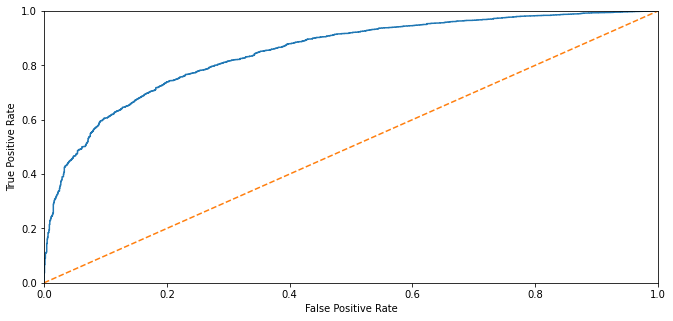

In [157]:
fpr, tpr, thresholds = roc_curve(target_train, predicted)

plt.figure(figsize=(11, 5))

plt.plot(fpr, tpr)

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show();

In [158]:

cat = ['Type', 'PaperlessBilling', 'PaymentMethod', 'gender', 'SeniorCitizen', 'Partner',
       'Dependents', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'MultipleLines']
param_grid = {
    'learning_rate': [0.05, 0.1, 0.3],
    'iterations': [50, 100, 200],

}

cat_model = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0,cat_features=cat)

cat_search = GridSearchCV(cat_model, param_grid, cv=8, scoring='roc_auc')
cat_search.fit(features_train_cb, target_train)

print(cat_search.best_params_)
print(cat_search.best_score_)

{'iterations': 200, 'learning_rate': 0.3}
0.8993226806579346


In [159]:
print(f'''Значение метрики ROC AUC на обучающей выборке для CatBoostClassifier''', cross_val_score(cat_search.best_estimator_, features_train, target_train,  
                         n_jobs = -1, 
                         scoring = 'roc_auc').mean())

Значение метрики ROC AUC на обучающей выборке для CatBoostClassifier nan


/opt/conda/lib/python3.9/site-packages/sklearn/model_selection/_validation.py:610: FitFailedWarning: Estimator fit failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/opt/conda/lib/python3.9/site-packages/sklearn/model_selection/_validation.py", line 593, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/opt/conda/lib/python3.9/site-packages/catboost/core.py", line 4716, in fit
    self._fit(X, y, cat_features, text_features, embedding_features, None, sample_weight, None, None, None, None, baseline, use_best_model,
  File "/opt/conda/lib/python3.9/site-packages/catboost/core.py", line 2021, in _fit
    train_params = self._prepare_train_params(
  File "/opt/conda/lib/python3.9/site-packages/catboost/core.py", line 1907, in _prepare_train_params
    train_pool = _build_train_pool(X, y, cat_features, text_features, embedding_features, pairs,
  File "/opt/conda/lib/python3.

In [160]:
cat_predicted = cat_search.best_estimator_.predict_proba(features_train_cb)[:, 1]

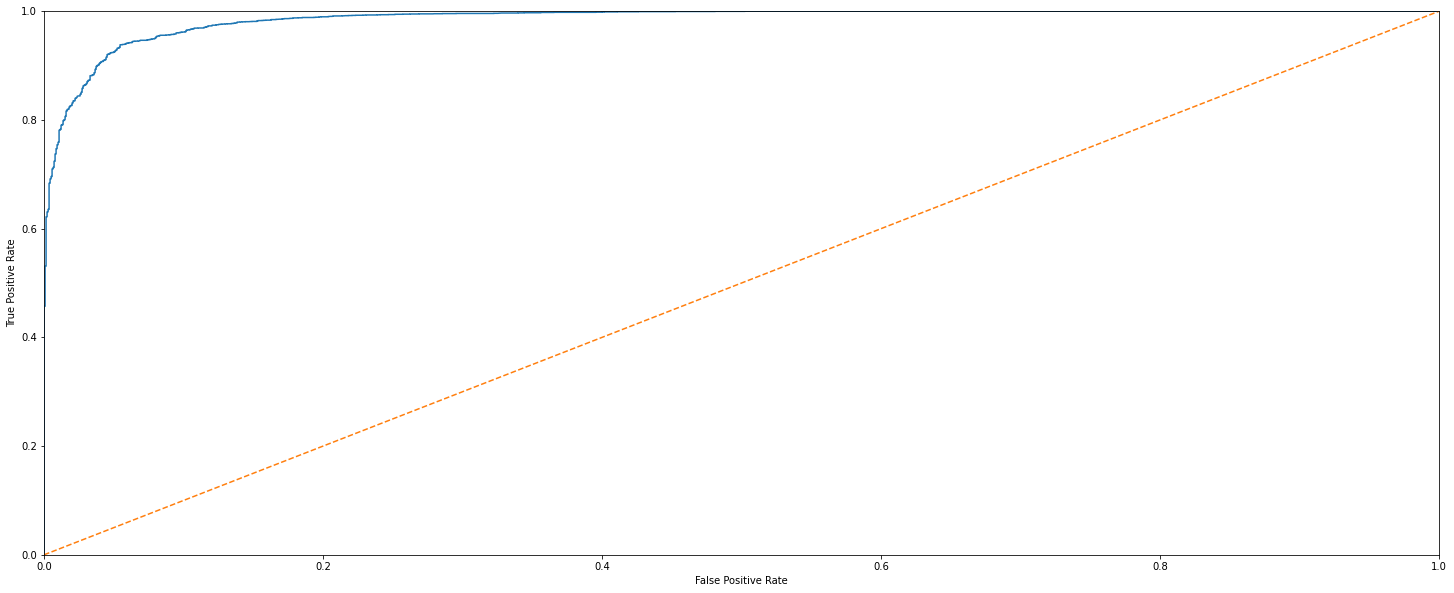

In [161]:
fpr, tpr, thresholds = roc_curve(target_train, cat_predicted)

plt.figure(figsize=(25, 10))

plt.plot(fpr, tpr)

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show();

In [162]:
cat_predicted_test = cat_search.best_estimator_.predict_proba(features_test_cb)[:, 1]

In [163]:
print('ROC-AUC score is', roc_auc_score(target_test, cat_predicted_test))

ROC-AUC score is 0.9153159311387159


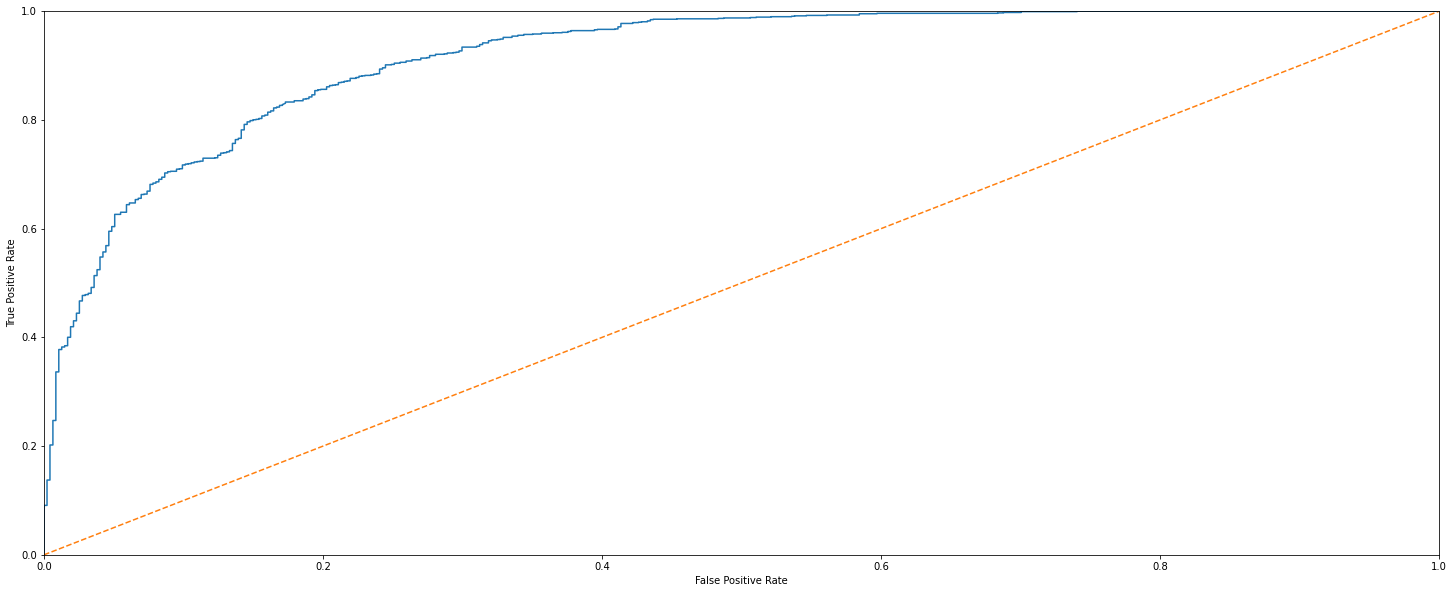

In [164]:
fpr, tpr, thresholds = roc_curve(target_test, cat_predicted_test)

plt.figure(figsize=(25, 10))

plt.plot(fpr, tpr)

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show();

[ 4.65460041  1.46171841  3.2346206  10.83859428  8.21040949 41.94091968
  1.12994627  0.87436744  0.88665815  0.5232365   1.61744698  0.71937361
  1.01100404  0.36957615  0.65360598  0.48834069  1.01553722  0.6504436
  1.46462279  2.82283365  0.49573087  0.65457252  0.98620237  1.01453719
  1.55001957  1.15141085  0.57038007  3.25518478  1.40656379  0.21306371
  0.6549888   0.57631767  0.88766544  0.51897004  0.28932171  1.20721466]
                            importance
Type                          4.654600
PaperlessBilling              1.461718
PaymentMethod                 3.234621
MonthlyCharges               10.838594
TotalCharges                  8.210409
duration                     41.940920
gender                        1.129946
SeniorCitizen                 0.874367
Partner                       0.886658
Dependents                    0.523237
InternetService               1.617447
OnlineSecurity                0.719374
OnlineBackup                  1.011004
DeviceProtection

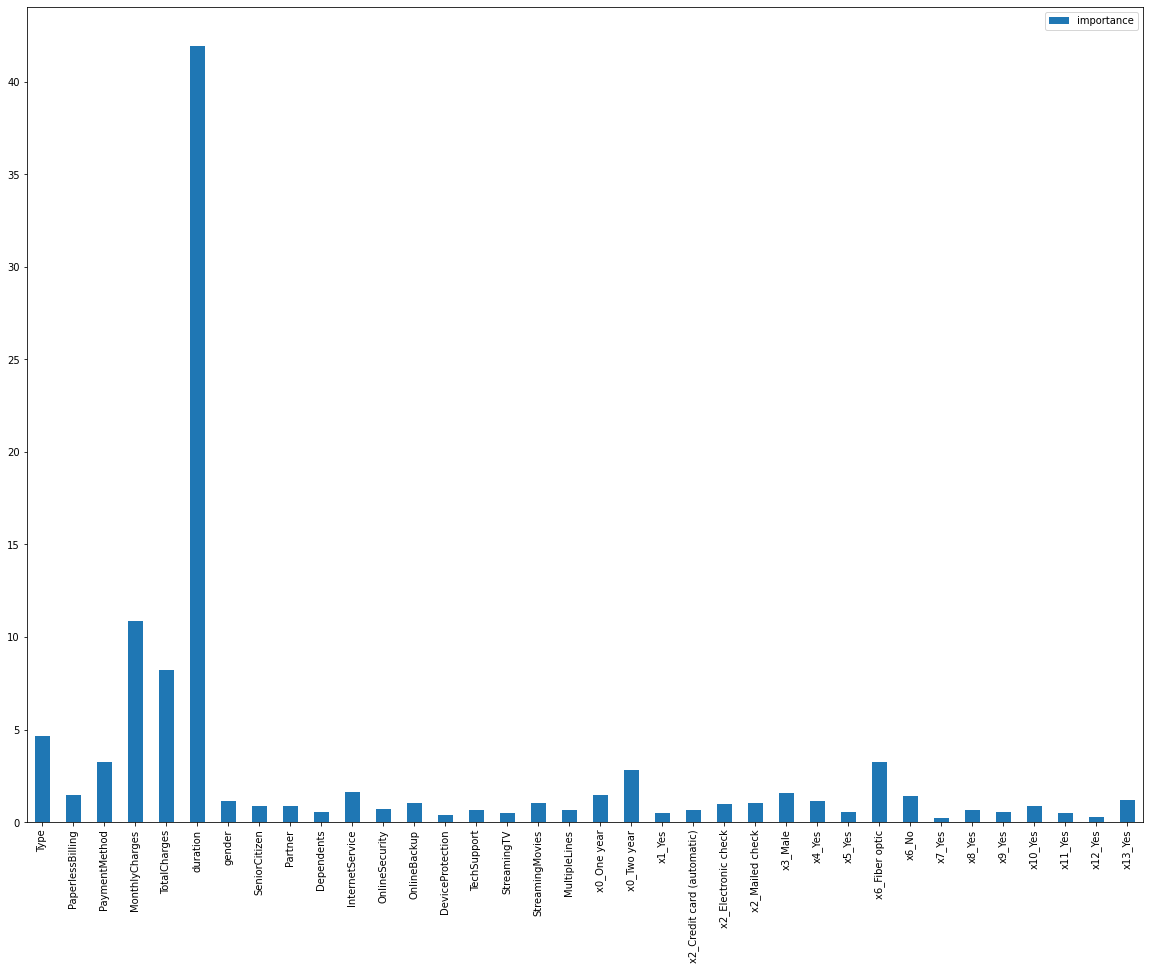

In [165]:
importances = cat_search.best_estimator_.feature_importances_
print(importances)
cat_importances = pd.DataFrame(importances, index = features_test_cb.columns, columns=['importance'])
print(cat_importances)
cat_importances.plot.bar(figsize=(20, 15))
ax.set_title("Feature importances")
plt.show();

<div style="border-radius: 15px; border: 3px solid indigo; padding: 15px;background:rgb(185, 176, 207)">
<b>Итоговый комментарий ревьюера:
</b> Молодец. Давай исправим критические моменты, а именно:<br>
    1.Графики<br>
    2.Выводы по результатам анализа<br>
    3.Корреляция<br>
    4.Кодирование<br>
    5.cv<br>
    6.даты выгрузки из бд(заполнение в end_date)<br>
    Также советую для кэтбуста использовать внутренний кодировщик
</div>


<div style="border-radius: 15px; border: 3px solid indigo; padding: 15px;background:rgb(185, 176, 207)">
<b>Итоговый комментарий ревьюера V2:
</b> Молодец. Осталось исправить пару моментов:<br>
    1.Графики(подписи)<br>
    2.Кодирование и масштабирование<br>
    3.pairplot(добавил пример)<br>
</div>

<div style="border-radius: 15px; border: 3px solid indigo; padding: 15px;background:rgb(185, 176, 207)">
<b>Итоговый комментарий ревьюера V3:
</b> Хорошо! Можешь приступать к отчетной части! Обрати, пожалуйста, внимание, что не во всех графиках есть подписи, также для кэтбуста, как и для деревянных моделей масштабирование не обязательно
</div>